
# Model 12: Hebbian Learning in a Neural Network

## Objective

Extend the interconnected neural network developed in Model 11 by introducing activity-dependent synaptic plasticity.

Unlike Model 11, where synaptic weights remained fixed, this model allows connections between neurons to strengthen through repeated coactivation.

Our goal is to investigate how neural networks can learn associations through experience and how these learned connections influence future neural activity.

## Research Questions

1. Can repeated activation of a group of neurons strengthen the connections between them?
2. How does repeated exposure affect the strength and structure of a neural network?
3. Can learned connections allow the network to activate associated neurons when given only partial stimulation?

## Hypothesis

Repeated coactivation of neurons will strengthen their mutual synaptic connections through Hebbian learning.

As training progresses, the network will develop stronger connections between frequently coactivated neurons, potentially allowing partial stimulation to reactivate previously learned activity patterns.

## Model Assumptions

- The network consists of six interconnected neurons.
- Neurons have binary activity states: 0 (inactive) or 1 (active).
- Synaptic weights are initially zero and constrained between 0 and 1.
- Connections strengthen according to bounded Hebbian learning.
- Self-connections are not permitted.
- Synaptic decay and inhibitory learning are excluded from this initial model.
- During training, neural activity patterns are externally imposed to isolate the learning mechanism.



## Mathematical Foundation

### Hebbian Learning

Hebbian learning is based on the principle that neurons that activate together strengthen their synaptic connections.

We use the bounded Hebbian learning rule introduced in Model 8:

$$
\Delta w_{ij} = \eta x_i x_j(1-w_{ij})
$$

where:

- $w_{ij}$ represents the connection strength from neuron $j$ to neuron $i$.
- $\eta$ represents the learning rate.
- $x_i$ represents the activity of the receiving neuron.
- $x_j$ represents the activity of the sending neuron.

The resulting update equation is:

$$
w_{ij}(t+1) = w_{ij}(t) + \eta x_i(t)x_j(t)(1-w_{ij}(t))
$$

The term $(1-w_{ij})$ prevents connection strengths from growing indefinitely.

### Matrix Representation

For a network of $n$ neurons, we represent neural activities using a vector:

$$
\mathbf{x} =
\begin{bmatrix}
x_1\\
x_2\\
\vdots\\
x_n
\end{bmatrix}
$$

Synaptic connections are represented by the weight matrix:

$$
W \in \mathbb{R}^{n \times n}
$$

We can calculate pairwise neural coactivation using the outer product:

$$
C = \mathbf{x}\mathbf{x}^T
$$

This produces a matrix where:

$$
C_{ij} = x_i x_j
$$

Using elementwise multiplication, the Hebbian learning rule becomes:

$$
\boxed{
W_{t+1} = W_t + \eta(\mathbf{x}\mathbf{x}^T)\odot(1-W_t)
}
$$

where $\odot$ represents elementwise multiplication.

We additionally set all diagonal entries to zero to prevent self-connections.



## Experiment 1: Learning a Neural Activity Pattern

### Objective

Investigate whether repeatedly presenting the same neural activity pattern strengthens connections between coactivated neurons.

### Experimental Setup

We initialize a network of six neurons with all synaptic weights equal to zero.

We repeatedly present the activity pattern:

$$
\mathbf{x} =
\begin{bmatrix}
1 & 1 & 0 & 1 & 0 & 0
\end{bmatrix}^T
$$

Neurons 1, 2, and 4 are active, while the remaining neurons are inactive.

The network undergoes 40 training epochs using a learning rate of 0.1.

### Prediction

Connections between neurons 1, 2, and 4 will strengthen with repeated training, approaching a maximum weight of 1.

Connections involving inactive neurons will remain at zero.


In [63]:

import numpy as np
import matplotlib.pyplot as plt

# Model parameters
num_neurons = 6
learning_rate = 0.1
epochs = 40

# Neural activity pattern
pattern = np.array([1, 1, 0, 1, 0, 0])

# Initialize synaptic weights
W = np.zeros((num_neurons, num_neurons))

# Record the initial weights
weight_history = [W.copy()]

# Training
for epoch in range(epochs):
    coactivation = np.outer(pattern, pattern)

    # Bounded Hebbian learning
    W += learning_rate * coactivation * (1 - W)

    # Prevent self-connections
    np.fill_diagonal(W, 0)

    weight_history.append(W.copy())

weight_history = np.array(weight_history)

print("Final weight matrix:")
print(np.round(W, 3))


Final weight matrix:
[[0.    0.985 0.    0.985 0.    0.   ]
 [0.985 0.    0.    0.985 0.    0.   ]
 [0.    0.    0.    0.    0.    0.   ]
 [0.985 0.985 0.    0.    0.    0.   ]
 [0.    0.    0.    0.    0.    0.   ]
 [0.    0.    0.    0.    0.    0.   ]]


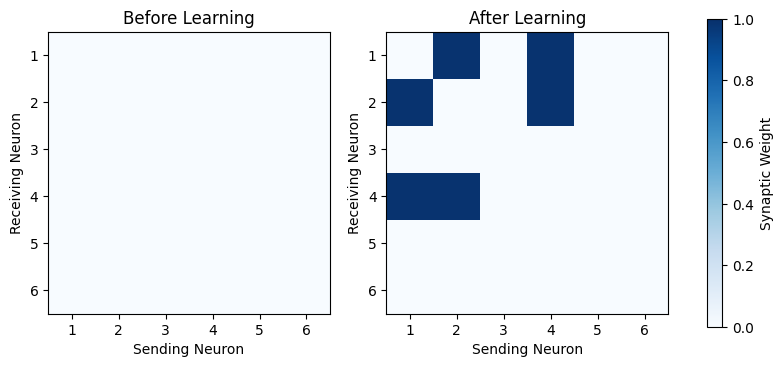

In [64]:

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

titles = ["Before Learning", "After Learning"]
matrices = [weight_history[0], weight_history[-1]]

for ax, matrix, title in zip(axes, matrices, titles):
    im = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)

    ax.set_title(title)
    ax.set_xlabel("Sending Neuron")
    ax.set_ylabel("Receiving Neuron")

    ax.set_xticks(range(num_neurons))
    ax.set_yticks(range(num_neurons))

    ax.set_xticklabels(range(1, num_neurons + 1))
    ax.set_yticklabels(range(1, num_neurons + 1))

fig.colorbar(im, ax=axes, label="Synaptic Weight")

plt.show()


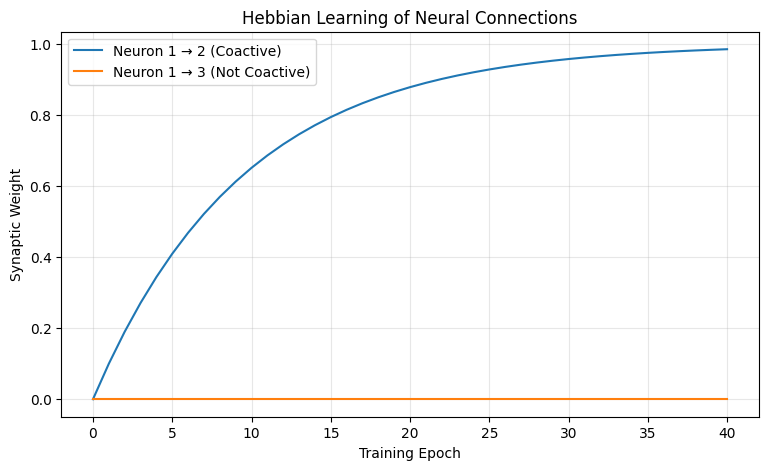

In [65]:

plt.figure(figsize=(9, 5))

# Coactive neurons
plt.plot(
    weight_history[:, 1, 0],
    label="Neuron 1 → 2 (Coactive)"
)

# Neurons that are not coactive
plt.plot(
    weight_history[:, 2, 0],
    label="Neuron 1 → 3 (Not Coactive)"
)

plt.xlabel("Training Epoch")
plt.ylabel("Synaptic Weight")
plt.title("Hebbian Learning of Neural Connections")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



## Experiment 1: Results and Discussion

### Observations

The network successfully strengthened synaptic connections between neurons that were repeatedly active together.

The weight matrix initially contained only zeros. After 40 training epochs, strong connections emerged between neurons 1, 2, and 4, while connections involving inactive neurons remained unchanged.

The learning curve also demonstrates that synaptic strengthening slows as weights approach their maximum value of 1.

For connections that are consistently coactive, the theoretical weight after $t$ epochs is:

$$
w_t = 1-(1-\eta)^t
$$

With a learning rate of 0.1 and 40 epochs:

$$
w_{40} = 1-0.9^{40} \approx 0.9852
$$

This agrees with the simulated connection strengths.

### Interpretation

These results demonstrate that repeated neural coactivation can produce structured synaptic connections through bounded Hebbian learning.

The network selectively strengthens connections between coactive neurons without strengthening unrelated connections.

However, this experiment only demonstrates synaptic learning. We have not yet established whether the resulting network can use its learned connections to retrieve an activity pattern from incomplete input.

### Next Experiment

We will investigate whether stimulating only part of a previously learned neural activity pattern allows the network to reconstruct the full pattern through its learned synaptic connections.



## Experiment 2: Partial Pattern Retrieval

### Objective

Investigate whether the network can reconstruct a previously learned neural activity pattern when only part of that pattern is initially activated.

### Experimental Setup

We use the weight matrix obtained after 40 epochs of Hebbian learning in Experiment 1.

The original training pattern was:

$$
\mathbf{x}_{\text{learned}} =
\begin{bmatrix}
1 & 1 & 0 & 1 & 0 & 0
\end{bmatrix}^T
$$

We initialize the network with a partial cue:

$$
\mathbf{x}_{\text{cue}} =
\begin{bmatrix}
1 & 0 & 0 & 0 & 0 & 0
\end{bmatrix}^T
$$

The network then updates its neural activities using the learned weight matrix:

$$
\mathbf{x}_{t+1}=H(W\mathbf{x}_t-\theta)
$$

We use an activation threshold of 0.8, with no continuing external stimulation after the initial cue.

We will also compare retrieval using an untrained network to determine whether successful reconstruction depends on the learned synaptic connections.

### Hypothesis

The trained network will reconstruct the original activity pattern through its strengthened connections.

The untrained network will fail to retrieve the pattern because its synaptic weights remain zero.


In [66]:

def retrieve_pattern(W, cue, threshold=0.8, steps=5):
    activities = cue.copy()
    history = [activities.copy()]

    for t in range(steps):
        inputs = W @ activities
        activities = (inputs >= threshold).astype(int)

        history.append(activities.copy())

    return np.array(history)


In [67]:

# Original learned pattern
learned_pattern = np.array([1, 1, 0, 1, 0, 0])

# Partial cue: only neuron 1 is active
cue = np.array([1, 0, 0, 0, 0, 0])

# Use the trained weights from Experiment 1
trained_W = weight_history[-1].copy()

# Compare against the original untrained network
untrained_W = weight_history[0].copy()

trained_history = retrieve_pattern(trained_W, cue)
untrained_history = retrieve_pattern(untrained_W, cue)

print("Original pattern:", learned_pattern)
print("Initial cue:     ", cue)
print("Trained result:  ", trained_history[-1])
print("Untrained result:", untrained_history[-1])

print(
    "Successful retrieval:",
    np.array_equal(trained_history[-1], learned_pattern)
)


Original pattern: [1 1 0 1 0 0]
Initial cue:      [1 0 0 0 0 0]
Trained result:   [1 1 0 1 0 0]
Untrained result: [0 0 0 0 0 0]
Successful retrieval: True


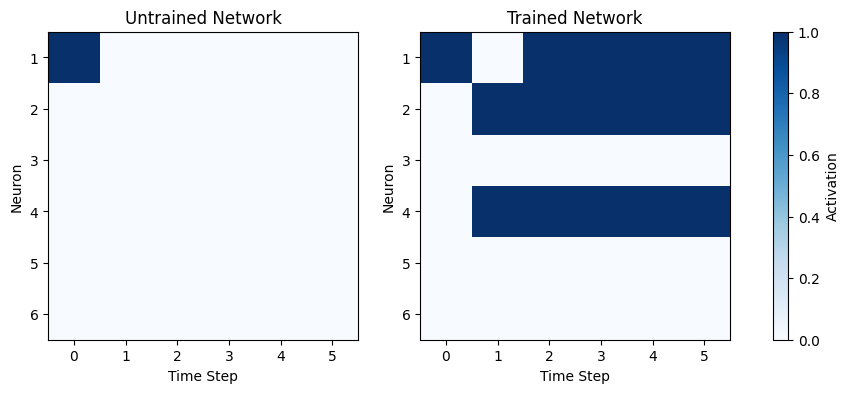

In [68]:

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

histories = [untrained_history, trained_history]
titles = ["Untrained Network", "Trained Network"]

for ax, history, title in zip(axes, histories, titles):
    im = ax.imshow(
        history.T,
        cmap="Blues",
        aspect="auto",
        vmin=0,
        vmax=1
    )

    ax.set_title(title)
    ax.set_xlabel("Time Step")
    ax.set_ylabel("Neuron")

    ax.set_xticks(range(history.shape[0]))
    ax.set_yticks(range(num_neurons))
    ax.set_yticklabels(range(1, num_neurons + 1))

fig.colorbar(im, ax=axes, label="Activation")

plt.show()



## Experiment 2: Results and Discussion

### Observations

The trained network successfully reconstructed the original activity pattern from a partial cue containing only neuron 1.

The original pattern was:

$$
\mathbf{x}_{\text{learned}} =
\begin{bmatrix}1 & 1 & 0 & 1 & 0 & 0\end{bmatrix}^T
$$

During retrieval, the network exhibited the following behavior:

- **Time 0:** Only neuron 1 was active.
- **Time 1:** Neurons 2 and 4 activated through their learned
  connections with neuron 1. Neuron 1 became inactive because
  the network has no self-connections.
- **Time 2:** Neurons 2 and 4 reactivated neuron 1 while
  maintaining each other's activity, reconstructing the
  original pattern.
- **Time 3 onward:** The reconstructed pattern remained
  stable without external stimulation.

In contrast, the untrained network became completely inactive after the first time step because its synaptic weights were zero.

### Interpretation

These results demonstrate that Hebbian learning can create synaptic connections capable of supporting associative memory retrieval.

Rather than requiring the complete original pattern as input, the trained network reconstructed the missing components through recurrent neural interactions.

The reconstructed pattern also remained stable after retrieval, demonstrating that learned recurrent connections can sustain neural activity without continuous external stimulation.

This stable activity pattern represents a fixed-point attractor under the network's activation rules.

### Limitations

This experiment involved only one stored memory and used a manually selected activation threshold.

Successful retrieval does not establish that the network can distinguish between multiple stored memories or recover patterns under substantial noise.

### Next Experiment

We will train the network on two different activity patterns and investigate whether they can be retrieved independently or whether overlapping neural representations cause interference.



## Experiment 3: Learning Multiple Memories

### Objective

Investigate whether a Hebbian neural network can store
and retrieve two different activity patterns, particularly
when those patterns share active neurons.

### Experimental Setup

We define two memories:

$$
\mathbf{x}_A =
\begin{bmatrix}1 & 1 & 0 & 1 & 0 & 0\end{bmatrix}^T
$$

$$
\mathbf{x}_B =
\begin{bmatrix}1 & 0 & 1 & 0 & 1 & 0\end{bmatrix}^T
$$

The memories share neuron 1 but otherwise involve
different groups of neurons.

We train three networks:

1. A network trained only on Memory A.
2. A network trained only on Memory B.
3. A network trained on both memories.

Each memory is presented for 40 training epochs,
using a learning rate of 0.1.

We then attempt to retrieve the memories from partial
cues using a threshold of 0.8.

### Hypothesis

Networks trained on individual memories will successfully
retrieve their respective patterns.

When both memories are stored in the same network,
their shared neuron may cause activity to spread between
the two representations.

This could produce interference, preventing the network
from independently retrieving the intended memory.


In [69]:

# Define the two memories
pattern_A = np.array([1, 1, 0, 1, 0, 0])
pattern_B = np.array([1, 0, 1, 0, 1, 0])


def train_network(patterns, learning_rate=0.1, epochs=40):
    weights = np.zeros((num_neurons, num_neurons))

    for pattern in patterns:
        for epoch in range(epochs):
            coactivation = np.outer(pattern, pattern)

            weights += learning_rate * coactivation * (1 - weights)

            np.fill_diagonal(weights, 0)

    return weights


# Train three separate networks
W_A = train_network([pattern_A])
W_B = train_network([pattern_B])
W_both = train_network([pattern_A, pattern_B])

print("Network trained on both memories:")
print(np.round(W_both, 3))


Network trained on both memories:
[[0.    0.985 0.985 0.985 0.985 0.   ]
 [0.985 0.    0.    0.985 0.    0.   ]
 [0.985 0.    0.    0.    0.985 0.   ]
 [0.985 0.985 0.    0.    0.    0.   ]
 [0.985 0.    0.985 0.    0.    0.   ]
 [0.    0.    0.    0.    0.    0.   ]]


In [70]:

# Partial cues
cue_A = np.array([0, 1, 0, 0, 0, 0])
cue_B = np.array([0, 0, 1, 0, 0, 0])

# Retrieve memories from individually trained networks
A_alone = retrieve_pattern(W_A, cue_A)
B_alone = retrieve_pattern(W_B, cue_B)

# Retrieve memories from the network trained on both
A_shared = retrieve_pattern(W_both, cue_A)
B_shared = retrieve_pattern(W_both, cue_B)

print("Memory A target:   ", pattern_A)
print("A trained alone:   ", A_alone[-1])
print("A trained with B:  ", A_shared[-1])

print()

print("Memory B target:   ", pattern_B)
print("B trained alone:   ", B_alone[-1])
print("B trained with A:  ", B_shared[-1])


Memory A target:    [1 1 0 1 0 0]
A trained alone:    [1 1 0 1 0 0]
A trained with B:   [1 1 1 1 1 0]

Memory B target:    [1 0 1 0 1 0]
B trained alone:    [1 0 1 0 1 0]
B trained with A:   [1 1 1 1 1 0]


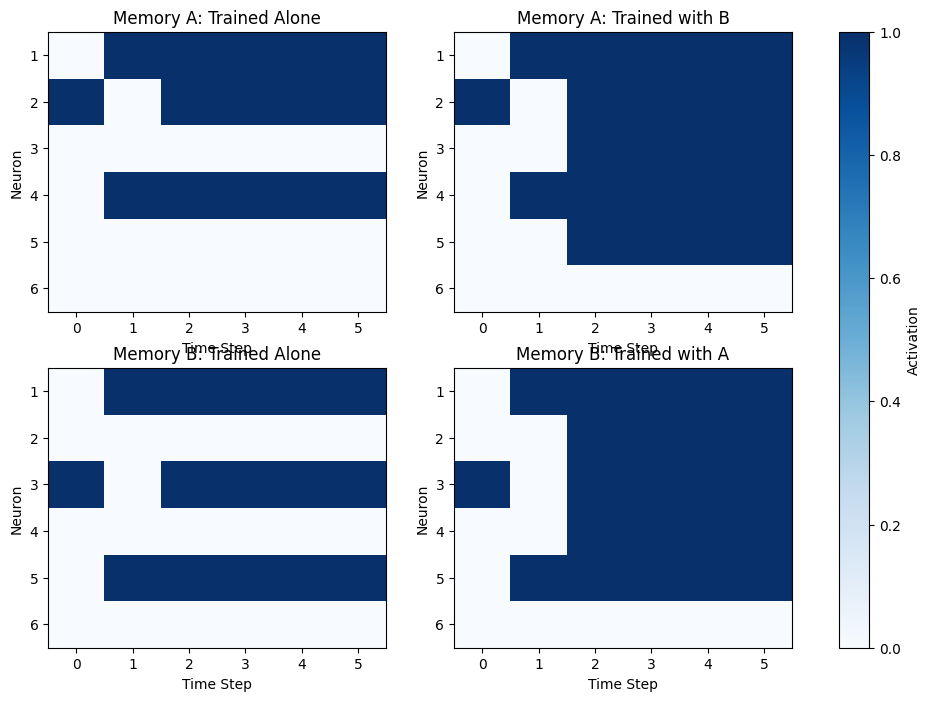

In [71]:

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

histories = [
    [A_alone, A_shared],
    [B_alone, B_shared]
]

titles = [
    ["Memory A: Trained Alone", "Memory A: Trained with B"],
    ["Memory B: Trained Alone", "Memory B: Trained with A"]
]

for row in range(2):
    for col in range(2):
        ax = axes[row, col]
        history = histories[row][col]

        im = ax.imshow(
            history.T,
            cmap="Blues",
            aspect="auto",
            vmin=0,
            vmax=1
        )

        ax.set_title(titles[row][col])
        ax.set_xlabel("Time Step")
        ax.set_ylabel("Neuron")

        ax.set_xticks(range(history.shape[0]))
        ax.set_yticks(range(num_neurons))
        ax.set_yticklabels(range(1, num_neurons + 1))

fig.colorbar(im, ax=axes.ravel().tolist(), label="Activation")
plt.show()



## Experiment 3: Results and Discussion

### Observations

When trained individually, both memories were successfully retrieved from their respective partial cues.

Memory A, represented by neurons 1, 2, and 4, was reconstructed after stimulating neuron 2. Similarly, Memory B, represented by neurons 1, 3, and 5, was reconstructed after stimulating neuron 3.

However, when both memories were stored in the same network, retrieval produced a different result.

In both cases, the network eventually activated neurons 1, 2, 3, 4, and 5, rather than selectively retrieving the intended memory.

### Interpretation

This behavior occurs because the two memories share neuron 1.

When retrieving Memory A, stimulating neuron 2 activates neurons 1 and 4 through their learned connections. However, neuron 1 also has strong connections with neurons 3 and 5 from training on Memory B.

Consequently, activation spreads into the second memory, producing a merged activity pattern.

This demonstrates **representational crosstalk**, where overlapping neural representations interfere with selective memory retrieval.

Importantly, the original memories have not been erased. Their synaptic connections remain intact, but the network cannot distinguish between the two learned patterns during retrieval.

### Conclusions

1. Hebbian learning allows the network to store multiple activity patterns within a shared weight matrix.
2. Individually trained memories can be successfully retrieved from partial cues.
3. Overlapping memories can produce unintended activation of neurons associated with other stored patterns.
4. Successful memory storage does not guarantee accurate or selective retrieval.

### Next Experiment

To investigate whether overlapping representations are responsible for the observed interference, we will train a network on two completely nonoverlapping memories.

If both memories can be retrieved independently, this will provide evidence that shared neural representations contribute to retrieval interference in our current model.



## Experiment 4: Nonoverlapping Memory Retrieval

### Objective

Investigate whether overlapping neural representations are responsible for the retrieval interference observed in Experiment 3.

### Experimental Setup

We use two memories with no shared active neurons:

$$
\mathbf{x}_A =
\begin{bmatrix}1&1&0&1&0&0\end{bmatrix}^T
$$

$$
\mathbf{x}_B =
\begin{bmatrix}0&0&1&0&1&1\end{bmatrix}^T
$$

Memory A activates neurons 1, 2, and 4, while Memory B activates neurons 3, 5, and 6.

We retain the parameters from Experiment 3:

- Learning rate: 0.1
- Training epochs per memory: 40
- Activation threshold: 0.8
- Retrieval duration: 5 time steps

We train both memories in one network and attempt to retrieve each memory using a single-neuron cue.

### Hypothesis

Without shared active neurons, Hebbian learning will produce separate groups of strengthened connections.

Consequently, stimulating one memory should not activate neurons belonging exclusively to the other memory.

We predict that both memories will be retrieved independently without the interference observed in Experiment 3.


In [72]:

# Define the nonoverlapping memories
pattern_A = np.array([1, 1, 0, 1, 0, 0])
pattern_B_disjoint = np.array([0, 0, 1, 0, 1, 1])

# Train both memories
W_disjoint = train_network([pattern_A, pattern_B_disjoint])

# Partial cues from Experiment 3
cue_A = np.array([0, 1, 0, 0, 0, 0])
cue_B = np.array([0, 0, 1, 0, 0, 0])

# Attempt retrieval
A_disjoint = retrieve_pattern(W_disjoint, cue_A)
B_disjoint = retrieve_pattern(W_disjoint, cue_B)

print("Memory A target:", pattern_A)
print("Memory A result:", A_disjoint[-1])
print("A retrieved:", np.array_equal(A_disjoint[-1], pattern_A))

print()

print("Memory B target:", pattern_B_disjoint)
print("Memory B result:", B_disjoint[-1])
print("B retrieved:", np.array_equal(B_disjoint[-1], pattern_B_disjoint))


Memory A target: [1 1 0 1 0 0]
Memory A result: [1 1 0 1 0 0]
A retrieved: True

Memory B target: [0 0 1 0 1 1]
Memory B result: [0 0 1 0 1 1]
B retrieved: True


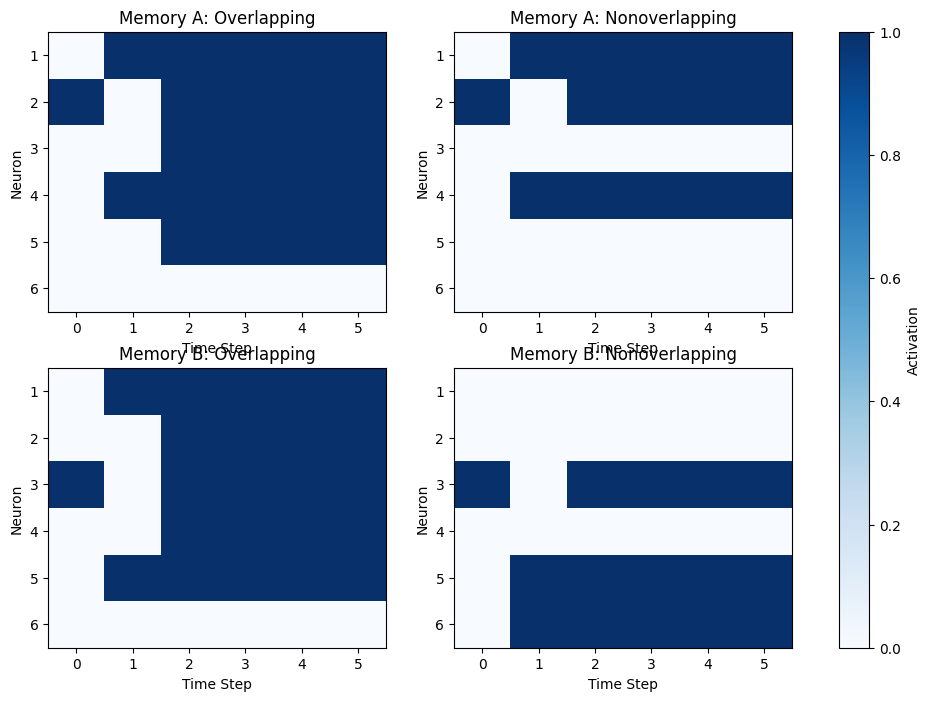

In [73]:

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

histories = [
    [A_shared, A_disjoint],
    [B_shared, B_disjoint]
]

titles = [
    ["Memory A: Overlapping", "Memory A: Nonoverlapping"],
    ["Memory B: Overlapping", "Memory B: Nonoverlapping"]
]

for row in range(2):
    for col in range(2):
        ax = axes[row, col]
        history = histories[row][col]

        im = ax.imshow(
            history.T, cmap="Blues",
            aspect="auto", vmin=0, vmax=1
        )

        ax.set_title(titles[row][col])
        ax.set_xlabel("Time Step")
        ax.set_ylabel("Neuron")
        ax.set_xticks(range(history.shape[0]))
        ax.set_yticks(range(num_neurons))
        ax.set_yticklabels(range(1, num_neurons + 1))

fig.colorbar(im, ax=axes.ravel().tolist(), label="Activation")
plt.show()


In [74]:

def count_intrusions(result, target):
    return np.sum((result == 1) & (target == 0))

tests = [
    ("A overlapping", A_shared[-1], pattern_A),
    ("A nonoverlapping", A_disjoint[-1], pattern_A),
    ("B overlapping", B_shared[-1], pattern_B),
    ("B nonoverlapping", B_disjoint[-1], pattern_B_disjoint)
]

for name, result, target in tests:
    intrusions = count_intrusions(result, target)

    print(f"{name}: {intrusions} intrusions")


A overlapping: 2 intrusions
A nonoverlapping: 0 intrusions
B overlapping: 2 intrusions
B nonoverlapping: 0 intrusions



## Experiment 4: Results and Discussion

### Observations

When the network was trained on two nonoverlapping memories, both patterns were successfully retrieved from their respective partial cues.

In contrast, the overlapping-memory network activated neurons associated with both memories, producing a merged pattern.

The measured intrusion counts were:

| Retrieval Test | Intrusions |
|---|---:|
| Memory A: Overlapping | 2 |
| Memory A: Nonoverlapping | 0 |
| Memory B: Overlapping | 2 |
| Memory B: Nonoverlapping | 0 |

Both overlapping retrieval tests produced two unintended neural activations, while neither nonoverlapping retrieval test produced any intrusions.

### Interpretation

These results demonstrate that overlapping neural representations can produce retrieval interference in our Hebbian network.

When memories share an active neuron, that neuron can develop strong connections with multiple learned patterns. During retrieval, activation can spread through these shared connections, unintentionally activating neurons associated with another memory.

When the memories share no active neurons, Hebbian learning produces separate groups of strengthened connections. As a result, neural activity remains confined to the intended memory.

This comparison supports the hypothesis that shared neural representations contribute to retrieval interference under our model's learning and activation rules.

### Conclusion

The network successfully stored and retrieved two nonoverlapping memories without interference.

However, when the memories shared an active neuron, retrieval produced a merged activity pattern rather than selectively reconstructing the intended memory.

These results suggest that additional mechanisms may be necessary for a neural network to distinguish overlapping memories during retrieval.



## Model Limitations

Although Model 12 successfully demonstrates Hebbian learning and associative retrieval, several limitations remain.

1. **Small network size:** The network consists of only six neurons, limiting the complexity and number of memories that can be represented.

2. **Binary neural activity:** Neurons are modeled as either active or inactive, rather than having continuous activity levels or more realistic firing dynamics.

3. **Simplified learning rule:** Synaptic connections strengthen through bounded Hebbian learning, without inhibition, synaptic weakening, or more sophisticated plasticity mechanisms.

4. **Fixed activation threshold:** All neurons use the same manually selected threshold, which influences the success of memory retrieval.

5. **Externally imposed training patterns:** Neural activity patterns are specified directly during learning rather than emerging through interactions with an environment.

6. **No forgetting mechanism:** Synaptic weights do not decay over time, meaning stored connections remain intact unless explicitly modified.

7. **Limited memory evaluation:** Experiments involve only one or two small patterns. Retrieval performance has not been evaluated across larger memory sets, varying degrees of overlap, or noisy inputs.

These limitations mean that the model should be interpreted as a simplified computational demonstration of associative memory rather than a biologically accurate representation of human memory.



## Final Conclusions

Model 12 extended the fixed-weight neural network developed in Model 11 by introducing activity-dependent synaptic learning.

Through four experiments, we investigated how neural networks form associations, retrieve learned patterns, and experience interference between stored representations.

### Key Findings

**Experiment 1: Hebbian Learning**

Repeated coactivation strengthened synaptic connections between active neurons. Connection strengths approached the theoretical bounded Hebbian learning prediction while unrelated connections remained unchanged.

**Experiment 2: Associative Retrieval**

The trained network successfully reconstructed a previously learned activity pattern from a partial cue. Recurrent connections also allowed the retrieved pattern to remain active without continued external stimulation.

**Experiment 3: Overlapping Memories**

When two memories shared a neuron, retrieval caused activity to spread between their representations, producing merged patterns rather than selective recall.

**Experiment 4: Nonoverlapping Memories**

When the memories shared no active neurons, both were retrieved independently with zero unintended activations. In comparison, overlapping memories each produced two intrusions.

### Overall Interpretation

These experiments demonstrate that Hebbian learning can establish associations capable of supporting memory retrieval in a recurrent neural network.

However, storing multiple patterns does not guarantee accurate retrieval. Overlapping representations can introduce interference, revealing a limitation of simple Hebbian learning and threshold-based activation.

The results highlight the importance of network structure and retrieval dynamics in determining whether stored memories can be accessed independently.

### Future Directions

Future models will investigate mechanisms that allow neural networks to distinguish between overlapping memories, including competitive activation, inhibition, and context-dependent retrieval.

Subsequent models will also introduce synaptic decay, rehearsal, and consolidation to investigate how learned representations weaken or persist over time.

The long-term objective is to develop a computational neural memory system capable of learning, retrieving, and forgetting multiple interacting memories.
